# Standard Course Q&A RAG System

**Objective:** build a standard Retrieval-Augmented Generation (RAG) system that answers student questions **only from course materials** of different file types (PDF, DOCX, CSV, TXT), and shows the sources of every answer.

**Pipeline**

`course files -> extract text -> clean -> chunk -> embeddings -> vector database (Chroma) -> retriever -> LLM (Gemini) -> answer + sources`


## 1. Setup

In [1]:
!pip install -q chromadb sentence-transformers pypdf python-docx google-genai

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.


In [2]:
import os
import re
import glob

import pandas as pd
from pypdf import PdfReader
from docx import Document
from docx.table import Table
from docx.text.paragraph import Paragraph

import json
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

os.makedirs("output", exist_ok=True)

## 2. Configuration
- **Embedding model:** `all-MiniLM-L6-v2` (small and fast, works on CPU). For Arabic questions or Arabic materials switch to the multilingual model written in the comment.
- **Chunks:** about 800 characters with 150 characters of overlap.
- **MAX_DISTANCE:** passages whose cosine distance is larger than this value are treated as irrelevant. If nothing relevant is found, the system answers that it could not find the answer, without calling the LLM.
- **Gemini model names change often**, so the notebook tries a list of models in order (see section 6).

In [3]:
# ---- Models
EMBED_MODEL = "sentence-transformers/all-MiniLM-L6-v2"   # English. For Arabic questions use "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
GEMINI_MODELS = ["gemini-3.5-flash-lite", "gemini-3.1-flash-lite", "gemini-3.8-flash"]   # tried in this order

# ---- Chunking and retrieval
CHUNK_SIZE = 800        # max characters per chunk
CHUNK_OVERLAP = 150     # characters shared between neighbouring chunks
TOP_K = 4               # passages retrieved for each question
MAX_DISTANCE = 0.75     # cosine distance above which a passage is treated as irrelevant

# ---- Storage
DB_DIR = "chroma_db"
COLLECTION = "course_materials"
DATA_DIR = None         # None = auto-detect, or set a path such as "/kaggle/input/.../courses"

In [4]:
try:
    from kaggle_secrets import UserSecretsClient
    os.environ["GEMINI_API_KEY"] = UserSecretsClient().get_secret("GEMINI_API_KEY")
    print("Gemini key loaded from Kaggle secrets")
except Exception:
    if not os.environ.get("GEMINI_API_KEY"):
        import getpass
        os.environ["GEMINI_API_KEY"] = getpass.getpass("Paste your Gemini API key: ")

Gemini key loaded from Kaggle secrets


## 3. Course materials

The knowledge base is built from **one folder per course**, each containing files of any supported type:

```
courses/
├── Machine_Learning/      (PDF, DOCX, TXT, CSV)
├── Databases/             (PDF, DOCX, TXT, CSV)
└── Python_Programming/    (PDF, DOCX, TXT, CSV)
```

**On Kaggle:** click `+ Add Input` > `Upload` > upload the `courses` folder as a new dataset, then add it to the notebook. The cell below finds it automatically.
The repository contains sample materials for 3 courses (`data/courses`). Replace them with your own course files for the real system.

### Step 1: extract text from each file type
- **PDF:** one unit per page (`pypdf`)
- **DOCX:** paragraphs and tables in document order (`python-docx`)
- **CSV:** one unit per row, written as `column: value | column: value` (`pandas`)
- **TXT:** the whole file

In [5]:
SUPPORTED = {".pdf", ".docx", ".csv", ".txt"}


def read_units(path):
    """Read one file and return a list of (location, text) units.

    PDF  -> one unit per page
    DOCX -> one unit (paragraphs and tables, in document order)
    CSV  -> one unit per row ("column: value | column: value")
    TXT  -> one unit
    """
    ext = os.path.splitext(path)[1].lower()

    if ext == ".pdf":
        reader = PdfReader(path)
        units = []
        for i, page in enumerate(reader.pages, start=1):
            text = page.extract_text() or ""
            text = re.sub(r"(?<!\n)\n(?!\n)", " ", text)      # join wrapped lines
            units.append((f"page {i}", text))
        return units

    if ext == ".docx":
        doc = Document(path)
        parts = []
        for child in doc.element.body.iterchildren():
            if child.tag.endswith("}p"):
                text = Paragraph(child, doc).text.strip()
                if text:
                    parts.append(text)
            elif child.tag.endswith("}tbl"):
                rows = [" | ".join(c.text.strip() for c in row.cells) for row in Table(child, doc).rows]
                parts.append("\n".join(rows))
        return [("", "\n\n".join(parts))]

    if ext == ".csv":
        try:
            df = pd.read_csv(path, encoding="utf-8-sig")
        except UnicodeDecodeError:
            df = pd.read_csv(path, encoding="latin-1")
        df = df.fillna("")
        units = []
        for i, row in df.iterrows():
            text = " | ".join(f"{col}: {val}" for col, val in row.items() if str(val).strip())
            units.append((f"row {i + 2}", text))               # +2 because the header is row 1
        return units

    if ext == ".txt":
        with open(path, encoding="utf-8", errors="ignore") as f:
            return [("", f.read())]

    return []

### Step 2: clean the text and split it into chunks
Cleaning removes control characters, fixes words split at line ends and normalizes whitespace. Chunking keeps paragraphs together when possible, falls back to sentences for long paragraphs, and adds an overlap between neighbouring chunks so that an idea cut at a boundary is not lost.

In [6]:
def clean_text(text):
    """Basic cleaning: remove control characters, fix hyphenated line breaks, normalise whitespace."""
    text = text.replace("\x00", " ")
    text = re.sub(r"[\x01-\x08\x0b\x0c\x0e-\x1f]", " ", text)
    text = re.sub(r"(\w)-\n([a-z])", r"\1\2", text)           # re-join words split at line ends
    text = re.sub(r"[ \t\xa0]+", " ", text)
    text = re.sub(r" ?\n ?", "\n", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()


def _hard_split(text, size):
    """Split a very long piece of text at spaces so that no part is longer than `size`."""
    parts = []
    while len(text) > size:
        cut = text.rfind(" ", 0, size)
        if cut <= 0:
            cut = size
        parts.append(text[:cut].strip())
        text = text[cut:].strip()
    if text:
        parts.append(text)
    return parts


def chunk_text(text, chunk_size=CHUNK_SIZE, overlap=CHUNK_OVERLAP):
    """Split text into chunks of roughly `chunk_size` characters.

    Paragraphs are kept together when possible, long paragraphs are split into
    sentences, and neighbouring chunks share about `overlap` characters of context.
    """
    text = clean_text(text)
    if not text:
        return []
    if len(text) <= chunk_size:
        return [text]

    pieces = []
    for para in re.split(r"\n\s*\n", text):
        para = para.strip()
        if not para:
            continue
        if len(para) <= chunk_size:
            pieces.append(para)
            continue
        for sentence in re.split(r"(?<=[.!?])\s+", para):
            sentence = sentence.strip()
            if not sentence:
                continue
            if len(sentence) <= chunk_size:
                pieces.append(sentence)
            else:
                pieces.extend(_hard_split(sentence, chunk_size))

    chunks, current = [], ""
    for piece in pieces:
        if current and len(current) + len(piece) + 1 > chunk_size:
            chunks.append(current)
            tail = current[-overlap:] if overlap > 0 else ""
            if " " in tail:
                tail = tail[tail.index(" ") + 1:]               # start at a word boundary
            current = (tail + " " + piece).strip()
        else:
            current = (current + "\n" + piece) if current else piece
    if current:
        chunks.append(current)
    return chunks

### Step 3: build the chunks for all courses
Every chunk keeps metadata (`course`, `source` file, `type`, `location` such as page or row number). This metadata is what allows **source attribution** and filtering by course.

In [7]:
def build_chunks(data_dir):
    """Walk data_dir/<course>/... and return a list of chunk dicts with metadata."""
    chunks = []
    for course in sorted(os.listdir(data_dir)):
        course_path = os.path.join(data_dir, course)
        if not os.path.isdir(course_path):
            continue
        course_name = course.replace("_", " ")
        for path in sorted(glob.glob(os.path.join(course_path, "**", "*"), recursive=True)):
            ext = os.path.splitext(path)[1].lower()
            if not os.path.isfile(path) or ext not in SUPPORTED:
                continue
            try:
                units = read_units(path)
            except Exception as e:
                print(f"Skipped {path}: {e}")
                continue
            for location, text in units:
                for chunk in chunk_text(text):
                    if len(chunk.split()) < 3:
                        continue
                    chunks.append({
                        "id": f"c{len(chunks):05d}",
                        "text": chunk,
                        "course": course_name,
                        "source": os.path.basename(path),
                        "type": ext[1:],
                        "location": location,
                    })
    return chunks

In [8]:
def has_course_folders(path):
    """True if `path` has no course files itself but its sub-folders do (courses/<course>/<files>)."""
    try:
        entries = os.listdir(path)
    except OSError:
        return False
    if any(os.path.splitext(e)[1].lower() in SUPPORTED for e in entries):
        return False
    for e in entries:
        sub = os.path.join(path, e)
        if os.path.isdir(sub) and any(os.path.splitext(f)[1].lower() in SUPPORTED for f in os.listdir(sub)):
            return True
    return False


def discover_data_dir(max_depth=6):
    for root in ["/kaggle/input", "data"]:
        if not os.path.isdir(root):
            continue
        for dirpath, dirnames, _ in os.walk(root):
            if dirpath[len(root):].count(os.sep) >= max_depth:
                dirnames[:] = []
                continue
            if has_course_folders(dirpath):
                return dirpath
    return None


DATA_PATH = DATA_DIR or discover_data_dir()
assert DATA_PATH, "No course folders found. Add your materials as an input dataset or set DATA_DIR."
print("Course materials folder:", DATA_PATH)
print("Courses:", [c for c in sorted(os.listdir(DATA_PATH)) if os.path.isdir(os.path.join(DATA_PATH, c))])

chunks = build_chunks(DATA_PATH)
chunks_df = pd.DataFrame(chunks)
print(f"\nTotal chunks: {len(chunks_df)}")

summary = chunks_df.groupby(["course", "type"]).agg(
    files=("source", "nunique"),
    chunks=("id", "count"),
    avg_chars=("text", lambda s: int(s.str.len().mean())),
)
display(summary)

Course materials folder: /kaggle/input/datasets/abdelazizelshourbgy/course-materials/courses
Courses: ['Databases', 'Machine_Learning', 'Python_Programming']

Total chunks: 67


files  chunks  avg_chars
course             type                          
Databases          csv       1      12        130
                   docx      1       3        704
                   pdf       1       4        699
                   txt       1       4        564
Machine Learning   csv       1      12        146
                   docx      1       4        680
                   pdf       1       5        695
                   txt       1       3        679
Python Programming csv       1      10        164
                   docx      1       3        728
                   pdf       1       3        722
                   txt       1       4        520

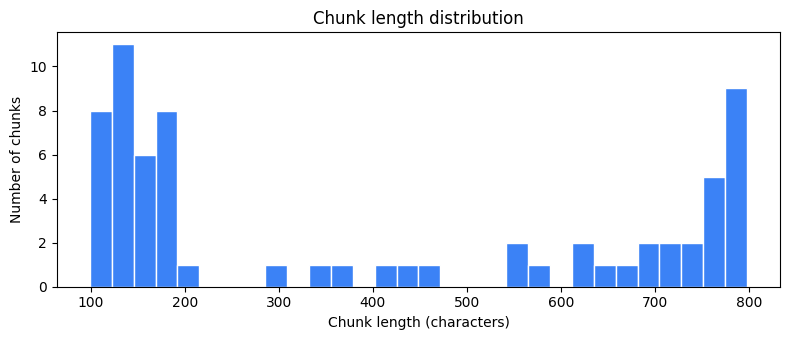

--- [pdf] Databases / 01_relational_model_and_sql.pdf page 1
Databases - Lecture 1: The Relational Model and SQL Basics 1.
Databases and DBMS A database is an organized collection of data.
A database management system (DBMS), such as MySQL, PostgreSQL or SQL Server, is the software that stores the data and handles queries, security, concurrency and recovery.
2.
The relational model In the relational model data is stored in tables, also called relations.
Eac 

--- [docx] Databases / 02_normalization.docx 
Databases - Lecture 2: Normalization
Why normalize?
Normalization is the process of organizing the tables of a database to reduce redundancy and to avoid update anomalies. Without it the same fact is stored in many places, which causes three kinds of anomalies: insertion anomalies (you cannot add a fact without adding another one), update anomalies (you must change many rows to update one fact) an 

--- [txt] Databases / 03_transactions_acid.txt 
Transactions and the ACID properties
WH

In [9]:
plt.figure(figsize=(8, 3.5))
plt.hist(chunks_df["text"].str.len(), bins=30, color="#3b82f6", edgecolor="white")
plt.xlabel("Chunk length (characters)")
plt.ylabel("Number of chunks")
plt.title("Chunk length distribution")
plt.tight_layout()
plt.savefig("output/chunk_length_distribution.png", dpi=150)
plt.show()

# Look at one chunk from each file type
for t in chunks_df["type"].unique():
    row = chunks_df[chunks_df["type"] == t].iloc[0]
    print(f"--- [{t}] {row['course']} / {row['source']} {row['location']}")
    print(row["text"][:400], "\n")

## 4. Embeddings and vector database
Every chunk is converted to a vector with a sentence-transformers model and stored in **ChromaDB** together with its metadata. Vectors are normalized and the index uses cosine distance (0 = identical direction, larger = less similar).

In [10]:
_embedder = None


def get_embedder():
    global _embedder
    if _embedder is None:
        from sentence_transformers import SentenceTransformer
        _embedder = SentenceTransformer(EMBED_MODEL)
    return _embedder


def embed_texts(texts, batch_size=64):
    vectors = get_embedder().encode(
        texts, batch_size=batch_size, normalize_embeddings=True, show_progress_bar=False
    )
    return vectors.tolist()


def build_index(chunks, db_dir=DB_DIR):
    """Embed all chunks and store them in a persistent Chroma collection (cosine distance)."""
    import chromadb

    client = chromadb.PersistentClient(path=db_dir)
    try:
        client.delete_collection(COLLECTION)
    except Exception:
        pass
    collection = client.get_or_create_collection(COLLECTION, metadata={"hnsw:space": "cosine"})
    for start in range(0, len(chunks), 128):
        batch = chunks[start:start + 128]
        collection.add(
            ids=[c["id"] for c in batch],
            documents=[c["text"] for c in batch],
            embeddings=embed_texts([c["text"] for c in batch]),
            metadatas=[{k: c[k] for k in ("course", "source", "type", "location")} for c in batch],
        )
    return collection


def load_index(db_dir=DB_DIR):
    import chromadb

    return chromadb.PersistentClient(path=db_dir).get_collection(COLLECTION)

In [11]:
collection = build_index(chunks, DB_DIR)
print("Chunks stored in the vector database:", collection.count())

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Chunks stored in the vector database: 67


## 5. Retriever
The question is embedded with the same model and the `TOP_K` closest chunks are returned. The optional `course` argument restricts the search to one course using the metadata filter.

In [12]:
def retrieve(question, collection, k=TOP_K, course=None):
    """Return the k most similar chunks (optionally only from one course)."""
    query_embedding = embed_texts([question])
    kwargs = {}
    if course and course != "All courses":
        kwargs["where"] = {"course": course}
    result = collection.query(query_embeddings=query_embedding, n_results=max(1, int(k)), **kwargs)
    hits = []
    for text, meta, dist in zip(result["documents"][0], result["metadatas"][0], result["distances"][0]):
        hits.append({"text": text, **meta, "distance": float(dist)})
    return hits

In [13]:
def show_hits(hits):
    for i, h in enumerate(hits, 1):
        where = f", {h['location']}" if h["location"] else ""
        print(f"[{i}] distance {h['distance']:.3f} | {h['course']} / {h['source']}{where}")
        print("    " + h["text"][:200].replace("\n", " ") + " ...\n")


q = "What is the difference between precision and recall?"
print("Question:", q, "\n")
show_hits(retrieve(q, collection))

print("=" * 80)
print("Same question restricted to the Databases course (it should find weaker matches):\n")
show_hits(retrieve(q, collection, course="Databases", k=2))

Question: What is the difference between precision and recall? 

[1] distance 0.453 | Machine Learning / 02_model_evaluation.docx
    on imbalanced data. If 95% of the emails are not spam, a model that always predicts not spam reaches 95% accuracy but detects no spam at all. Precision answers the question: of all the examples predic ...

[2] distance 0.523 | Machine Learning / 02_model_evaluation.docx
    / (precision + recall). It is high only when both precision and recall are high, so it is a better summary than accuracy for imbalanced datasets. Metric | Formula | Use it when Accuracy | (TP + TN) /  ...

[3] distance 0.578 | Machine Learning / 02_model_evaluation.docx
    Machine Learning - Lecture 2: Evaluating Classification Models The confusion matrix A confusion matrix compares the predicted classes with the true classes. For a binary problem it contains four count ...

[4] distance 0.677 | Python Programming / 01_data_structures.pdf, page 1
    can be used as dictionary keys. T

## 6. Generation with Gemini
The retrieved passages are numbered and given to the LLM together with strict rules:
- answer **only** from the excerpts,
- say `I couldn't find this in the course materials.` when the answer is not there,
- cite the excerpts as `[1]`, `[2]`.

Two safety layers reduce hallucination: (1) passages above `MAX_DISTANCE` are dropped before the LLM is called, and (2) the prompt forbids outside knowledge. If the LLM is unavailable (for example the free quota is used up), the system still returns the retrieved passages.

In [14]:
NOT_FOUND = "I couldn't find this in the course materials."

SYSTEM_PROMPT = """You are a teaching assistant that answers student questions about university courses.

Rules:
1. Answer ONLY from the numbered course excerpts provided. Never use outside knowledge, even if you know the answer.
2. If the excerpts do not contain the answer, reply exactly: I couldn't find this in the course materials.
3. Cite the excerpts you used with their numbers in square brackets, for example [1] or [2][3].
4. Be clear and concise. Write in the same language as the question.
5. Write formulas in plain text, for example F1 = 2 * precision * recall / (precision + recall). Do not use LaTeX or $ signs."""

_client = None


def get_client():
    global _client
    if _client is None:
        from google import genai

        key = os.environ.get("GEMINI_API_KEY") or os.environ.get("GOOGLE_API_KEY")
        if not key:
            raise RuntimeError("GEMINI_API_KEY is not set")
        _client = genai.Client(api_key=key)
    return _client


def build_prompt(question, hits):
    blocks = []
    for i, h in enumerate(hits, start=1):
        where = f", {h['location']}" if h["location"] else ""
        blocks.append(f"[{i}] ({h['course']} - {h['source']}{where})\n{h['text']}")
    context = "\n\n".join(blocks)
    return f"Course excerpts:\n\n{context}\n\nQuestion: {question}"


def generate_answer(question, hits):
    """Ask Gemini to answer from the excerpts. Tries each model in GEMINI_MODELS in order."""
    from google.genai import types

    prompt = build_prompt(question, hits)
    errors = []
    for model in GEMINI_MODELS:
        try:
            response = get_client().models.generate_content(
                model=model,
                contents=prompt,
                config=types.GenerateContentConfig(system_instruction=SYSTEM_PROMPT, temperature=0.2),
            )
            text = (response.text or "").strip()
            if text:
                return text, model, None
            errors.append(f"{model}: empty response")
        except Exception as e:
            errors.append(f"{model}: {str(e)[:160]}")
    return None, None, " | ".join(errors)


def answer_question(question, collection, k=TOP_K, course=None):
    """Full RAG step: retrieve -> filter by relevance -> generate a grounded answer."""
    hits = retrieve(question, collection, k=k, course=course)
    relevant = [h for h in hits if h["distance"] <= MAX_DISTANCE]
    if not relevant:
        return {"answer": NOT_FOUND, "sources": [], "hits": hits, "model": None, "error": None}

    answer, model, error = generate_answer(question, relevant)
    if answer is None:
        # The LLM is unavailable (quota, network, ...): still show the retrieved passages.
        answer = "The language model could not be reached, so here are the most relevant passages from the course materials."
        return {"answer": answer, "sources": relevant, "hits": hits, "model": None, "error": error}

    normalized = answer.lower().replace("\u2019", "'").rstrip(" .")
    if NOT_FOUND.lower().rstrip(".") in normalized:
        return {"answer": NOT_FOUND, "sources": [], "hits": hits, "model": model, "error": None}
    return {"answer": answer, "sources": relevant, "hits": hits, "model": model, "error": None}

In [15]:
# Gemini model names change often: list the Flash models available for your key
# and make sure the names in GEMINI_MODELS exist.
client = get_client()
available = sorted(m.name.replace("models/", "") for m in client.models.list())
print("Available Flash models:", [m for m in available if "flash" in m])
print("Configured models:     ", GEMINI_MODELS)

Available Flash models: ['gemini-2.5-flash', 'gemini-2.5-flash-image', 'gemini-2.5-flash-lite', 'gemini-2.5-flash-native-audio-latest', 'gemini-2.5-flash-native-audio-preview-09-2025', 'gemini-2.5-flash-native-audio-preview-12-2025', 'gemini-2.5-flash-preview-tts', 'gemini-3-flash-preview', 'gemini-3.1-flash-image', 'gemini-3.1-flash-image-preview', 'gemini-3.1-flash-lite', 'gemini-3.1-flash-lite-image', 'gemini-3.1-flash-lite-preview', 'gemini-3.1-flash-live-preview', 'gemini-3.1-flash-tts-preview', 'gemini-3.5-flash', 'gemini-3.5-flash-lite', 'gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash', 'gemini-3.8-flash-lite-tts', 'gemini-3.8-flash-tts', 'gemini-flash-latest', 'gemini-flash-lite-latest', 'gemini-omni-1.1-flash', 'gemini-omni-1.2-flash', 'gemini-omni-flash-preview']
Configured models:      ['gemini-3.5-flash-lite', 'gemini-3.1-flash-lite', 'gemini-3.8-flash']


In [16]:
def show(result):
    print("ANSWER:", result["answer"])
    if result.get("model"):
        print(f"(model: {result['model']})")
    if result.get("error"):
        print("LLM error:", result["error"])
    if result["sources"]:
        print("\nSOURCES:")
        for i, s in enumerate(result["sources"], 1):
            where = f", {s['location']}" if s["location"] else ""
            print(f"  [{i}] {s['course']} / {s['source']}{where}  (distance {s['distance']:.2f})")
    print()


show(answer_question("What is overfitting and how can it be reduced?", collection))

ANSWER: Overfitting happens when a model learns the training data too closely, including its noise, so it performs very well on the training set but poorly on new data [2]. 

Overfitting can be reduced by:
- Collecting more training data [1]
- Using a simpler model [1]
- Applying regularization (L1 or L2) [1]
- Using dropout in neural networks [1]
- Stopping the training early [1]
- Using cross-validation to detect it [1]
(model: gemini-3.5-flash-lite)

SOURCES:
  [1] Machine Learning / 01_introduction_to_ml.pdf, page 1  (distance 0.37)
  [2] Machine Learning / 01_introduction_to_ml.pdf, page 1  (distance 0.51)
  [3] Machine Learning / 03_gradient_descent_notes.txt  (distance 0.65)
  [4] Machine Learning / ml_glossary.csv, row 13  (distance 0.67)



## 7. Try different kinds of questions
The last question is **out of scope** on purpose: the system should refuse instead of answering from the LLM's own knowledge. The free Gemini tier has a low requests-per-minute limit, so the loop waits between questions.

In [17]:
DEMO_QUESTIONS = [
    ("What is overfitting and how can it be reduced?", None),                 # Machine Learning (PDF)
    ("How is the F1 score calculated?", None),                                # Machine Learning (DOCX)
    ("What do the letters in ACID stand for?", None),                         # Databases (TXT)
    ("Which SQL command removes all rows but keeps the table?", "Databases"), # Databases (CSV) + course filter
    ("How do I remove duplicates from a list in Python?", None),              # Python (CSV / PDF)
    ("Who won the 2022 FIFA World Cup?", None),                               # out of scope
]

for q, course in DEMO_QUESTIONS:
    print("=" * 80)
    print("Q:", q, f"[course filter: {course}]" if course else "")
    show(answer_question(q, collection, course=course))
    time.sleep(6)

Q: What is overfitting and how can it be reduced? 
ANSWER: Overfitting happens when a model learns the training data too closely, including its noise, so it performs very well on the training set but poorly on new data [2].

Overfitting can be reduced by:
- Collecting more training data [1]
- Using a simpler model [1]
- Applying regularization (L1 or L2) [1]
- Using dropout in neural networks [1]
- Stopping the training early [1]
- Using cross-validation to detect it [1]
(model: gemini-3.5-flash-lite)

SOURCES:
  [1] Machine Learning / 01_introduction_to_ml.pdf, page 1  (distance 0.37)
  [2] Machine Learning / 01_introduction_to_ml.pdf, page 1  (distance 0.51)
  [3] Machine Learning / 03_gradient_descent_notes.txt  (distance 0.65)
  [4] Machine Learning / ml_glossary.csv, row 13  (distance 0.67)

Q: How is the F1 score calculated? 
ANSWER: The F1 score is calculated as the harmonic mean of precision and recall using the formula: F1 = 2 * precision * recall / (precision + recall) [1][2]

## 8. Evaluation
No labeled benchmark exists for this small knowledge base, so a small test set was written by hand: each question lists the file(s) that contain the answer.

**Retrieval metrics** (no LLM involved):
- **Hit@1:** the correct file is the top result
- **Hit@K:** the correct file is among the `TOP_K` results
- **MRR:** mean reciprocal rank of the first correct result

**Out-of-scope questions:** the share of unrelated questions that the distance threshold rejects before the LLM is called.

In [18]:
TEST_SET = [
    ("What is overfitting and how can it be reduced?", ["01_introduction_to_ml.pdf"]),
    ("What is the difference between supervised and unsupervised learning?", ["01_introduction_to_ml.pdf"]),
    ("How is the F1 score calculated?", ["02_model_evaluation.docx"]),
    ("What does the learning rate do in gradient descent?", ["03_gradient_descent_notes.txt"]),
    ("What is the difference between L1 and L2 regularization?", ["03_gradient_descent_notes.txt"]),
    ("What is a hyperparameter?", ["ml_glossary.csv", "01_introduction_to_ml.pdf"]),
    ("What is a foreign key?", ["01_relational_model_and_sql.pdf"]),
    ("What is the difference between INNER JOIN and LEFT JOIN?", ["01_relational_model_and_sql.pdf", "sql_cheatsheet.csv"]),
    ("What does Third Normal Form require?", ["02_normalization.docx"]),
    ("What do the letters in ACID stand for?", ["03_transactions_acid.txt"]),
    ("Which SQL command removes all rows quickly but keeps the table?", ["sql_cheatsheet.csv"]),
    ("What is the difference between a list and a tuple in Python?", ["01_data_structures.pdf"]),
    ("What are the four pillars of object-oriented programming?", ["02_object_oriented_programming.docx"]),
    ("How do I handle errors with try and except?", ["03_exceptions_and_files.txt"]),
    ("How do I remove duplicates from a list?", ["python_faq.csv", "01_data_structures.pdf"]),
]

OUT_OF_SCOPE = [
    "Who won the 2022 FIFA World Cup?",
    "What is the capital of Japan?",
    "Give me a recipe for koshary.",
    "What is the weather in Cairo today?",
]

rows = []
for question, expected in TEST_SET:
    hits = retrieve(question, collection, k=TOP_K)
    found = [h["source"] for h in hits]
    rank = next((i for i, s in enumerate(found, 1) if s in expected), None)
    rows.append({
        "question": question,
        "expected": " / ".join(expected),
        "top1": found[0],
        "hit_rank": rank,
        "top1_distance": round(hits[0]["distance"], 3),
    })
eval_df = pd.DataFrame(rows)

hit_at_1 = float((eval_df["hit_rank"] == 1).mean())
hit_at_k = float(eval_df["hit_rank"].notna().mean())
mrr = float((1 / eval_df["hit_rank"]).fillna(0).mean())

oos_rows = []
for q in OUT_OF_SCOPE:
    top = retrieve(q, collection, k=1)[0]
    oos_rows.append({
        "question": q,
        "top1": top["source"],
        "top1_distance": round(top["distance"], 3),
        "rejected_by_threshold": top["distance"] > MAX_DISTANCE,
    })
oos_df = pd.DataFrame(oos_rows)
refusal_rate = float(oos_df["rejected_by_threshold"].mean())

print(f"In-scope questions: {len(eval_df)}")
print(f"Hit@1: {hit_at_1:.2f} | Hit@{TOP_K}: {hit_at_k:.2f} | MRR: {mrr:.2f}")
print(f"Out-of-scope questions rejected by the threshold: {refusal_rate:.0%} ({int(oos_df['rejected_by_threshold'].sum())}/{len(oos_df)})")
print(f"Top-1 distance, in-scope:     min {eval_df['top1_distance'].min():.3f}, max {eval_df['top1_distance'].max():.3f}")
print(f"Top-1 distance, out-of-scope: min {oos_df['top1_distance'].min():.3f}, max {oos_df['top1_distance'].max():.3f}")
print(f"Current MAX_DISTANCE = {MAX_DISTANCE}  (it should sit between the two ranges)")

display(eval_df)
display(oos_df)

eval_df.to_csv("output/evaluation_results.csv", index=False)
with open("output/metrics.json", "w") as f:
    json.dump({
        "in_scope_questions": len(eval_df),
        "hit_at_1": hit_at_1,
        f"hit_at_{TOP_K}": hit_at_k,
        "mrr": mrr,
        "out_of_scope_questions": len(oos_df),
        "out_of_scope_rejected": refusal_rate,
        "max_distance": MAX_DISTANCE,
        "embed_model": EMBED_MODEL,
        "chunks": len(chunks_df),
    }, f, indent=2)

In-scope questions: 15
Hit@1: 1.00 | Hit@4: 1.00 | MRR: 1.00
Out-of-scope questions rejected by the threshold: 100% (4/4)
Top-1 distance, in-scope:     min 0.186, max 0.661
Top-1 distance, out-of-scope: min 0.849, max 0.919
Current MAX_DISTANCE = 0.75  (it should sit between the two ranges)


,question,expected,top1,hit_rank,top1_distance
0,What is overfitting and how can it be reduced?,01_introduction_to_ml.pdf,01_introduction_to_ml.pdf,1,0.374
1,What is the difference between supervised and ...,01_introduction_to_ml.pdf,01_introduction_to_ml.pdf,1,0.418
2,How is the F1 score calculated?,02_model_evaluation.docx,02_model_evaluation.docx,1,0.603
3,What does the learning rate do in gradient des...,03_gradient_descent_notes.txt,03_gradient_descent_notes.txt,1,0.326
4,What is the difference between L1 and L2 regul...,03_gradient_descent_notes.txt,03_gradient_descent_notes.txt,1,0.419
5,What is a hyperparameter?,ml_glossary.csv / 01_introduction_to_ml.pdf,ml_glossary.csv,1,0.186
6,What is a foreign key?,01_relational_model_and_sql.pdf,01_relational_model_and_sql.pdf,1,0.408
7,What is the difference between INNER JOIN and ...,01_relational_model_and_sql.pdf / sql_cheatshe...,01_relational_model_and_sql.pdf,1,0.369
8,What does Third Normal Form require?,02_normalization.docx,02_normalization.docx,1,0.451
9,What do the letters in ACID stand for?,03_transactions_acid.txt,03_transactions_acid.txt,1,0.661


,question,top1,top1_distance,rejected_by_threshold
0,Who won the 2022 FIFA World Cup?,02_model_evaluation.docx,0.919,True
1,What is the capital of Japan?,ml_glossary.csv,0.888,True
2,Give me a recipe for koshary.,01_introduction_to_ml.pdf,0.849,True
3,What is the weather in Cairo today?,ml_glossary.csv,0.919,True


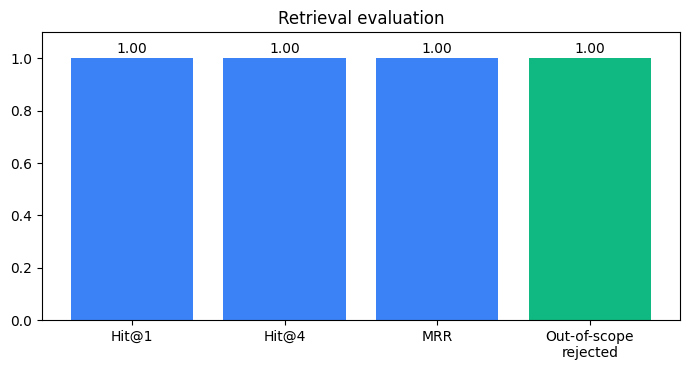

In [19]:
labels = ["Hit@1", f"Hit@{TOP_K}", "MRR", "Out-of-scope\nrejected"]
values = [hit_at_1, hit_at_k, mrr, refusal_rate]

plt.figure(figsize=(7, 3.8))
bars = plt.bar(labels, values, color=["#3b82f6", "#3b82f6", "#3b82f6", "#10b981"])
for bar, v in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width() / 2, v + 0.02, f"{v:.2f}", ha="center")
plt.ylim(0, 1.1)
plt.title("Retrieval evaluation")
plt.tight_layout()
plt.savefig("output/retrieval_metrics.png", dpi=150)
plt.show()

## 9. Conclusion
- A complete RAG pipeline was built: extraction from 4 file types, cleaning, chunking with overlap, embeddings, a ChromaDB vector store, a retriever with course filtering, and a Gemini-based generator.
- Every answer comes with its sources (course, file, page or row), and out-of-scope questions are rejected.
- The app (`app.py`) wraps the same pipeline in a Gradio interface for deployment on Hugging Face Spaces.

**Limitations:** the evaluation uses a small hand-made test set on sample materials; scanned PDFs (images) are not supported without OCR; chunking is character-based; the answer quality depends on the LLM and on its free-tier limits.

**Possible improvements:** hybrid search (BM25 + embeddings), a re-ranker, OCR for scanned files, conversation memory, and automatic answer evaluation (faithfulness).